# Çevresel Ses Tanıma ve Otomatik Etiketleme

**Hazırlayan — Esra Gögebakan**

## Problem ve amaç
Beş saniyelik bir ses kaydının akustik özelliklerinden, kaydın 10 çevresel ses türünden hangisine ait olduğunu tahmin edebilir miyim?

Ses arşivlerinde aranan kaydı bulmak için dosyaları tek tek dinlemek zaman alabilir. Bu projede kısa bir kaydı inceleyip kullanıcıya Türkçe bir ses etiketi öneren uygulama geliştirdim. Çalışmayı Python ve Google Colab üzerinde gerçekleştirdim.

| Proje bilgisi | Açıklama |
|---|---|
| Veri seti | ESC-10 |
| Problem türü | Çok sınıflı sınıflandırma |
| Kullanıcı girdisi | Kısa bir WAV kaydı |
| Model girdisi | Sesten hesaplanan 16 sayısal özellik |
| Hedef | Gerçek ses türü |
| Uygulama çıktısı | Örneğin köpek havlaması etiketi |

Defterde önce kayıtları tanıdım ve özellik tablosunu hazırladım. Ardından iki modeli karşılaştırıp seçtiğim modeli ayrı test grubunda değerlendirdim. Son bölümde tahmin fonksiyonunu ve örnek çıktıları gösterdim.

## Veri setini tanıma
ESC-50 içindeki `esc10` sütunu True olan satırları seçerek ESC-10 alt kümesini oluşturdum. Bu alt kümede her biri beş saniyelik 400 kayıt ve 10 ses türü bulunuyor. Her türden 40 kayıt olması, sınıfların örnek sayısı bakımından dengeli olduğunu gösteriyor.

İlk okuduğum CSV, ses dosyalarını tanımlayan kayıt listesidir. Seslerin kendisini sonraki hücrelerde indiriyorum. Model girdisi olarak kullanacağım sayısal özellik tablosunu da daha sonra kendim oluşturuyorum.

| Sütun | Anlamı |
|---|---|
| `filename` | WAV dosyasının adı |
| `category` | Kaydın gerçek ses etiketi |
| `fold` | Kaydın hazır grup numarası |
| `esc10` | Kaydın ESC-10 alt kümesine dahil olup olmadığı |

`value_counts()` ile sınıf sayılarını, `head()` ile ilk kayıtların yapısını kontrol ettim.

Veri kaynağı — Karol J. Piczak, ESC (2015). ESC-10 alt kümesi CC BY lisansıyla sunuluyor. [Veri seti ve atıf bilgisi](https://github.com/karolpiczak/ESC-50)

In [1]:
import pandas as pd

# Ses dosyalarının adlarını ve gerçek etiketlerini içeren tabloyu okuyorum.
veri_adresi = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master/meta/esc50.csv"
tum_kayitlar = pd.read_csv(veri_adresi)

# İlk projede kullanacağım 10 ses türüne ait kayıtları seçiyorum.
ses_kayitlari = tum_kayitlar.loc[tum_kayitlar["esc10"]].copy()

print("Toplam kayıt sayısı:", len(ses_kayitlari))
print("Farklı ses türü sayısı:", ses_kayitlari["category"].nunique())

# Her ses türünden kaç kayıt olduğunu gösteriyorum.
display(ses_kayitlari["category"].value_counts().rename("Kayıt sayısı"))

# Tablodaki ilk 5 kaydı inceliyorum.
display(ses_kayitlari[["filename", "category", "fold"]].head())

Toplam kayıt sayısı: 400
Farklı ses türü sayısı: 10


,Kayıt sayısı
category,
dog,40
chainsaw,40
crackling_fire,40
helicopter,40
rain,40
crying_baby,40
clock_tick,40
sneezing,40
rooster,40


,filename,category,fold
0,1-100032-A-0.wav,dog,1
14,1-110389-A-0.wav,dog,1
24,1-116765-A-41.wav,chainsaw,1
54,1-17150-A-12.wav,crackling_fire,1
55,1-172649-A-40.wav,helicopter,1


## Sesleri dinleme ve dalga biçimlerini inceleme
Önce bir yağmur ve bir köpek havlaması kaydı seçtim. Grafikte yatay eksen zamanı, dikey eksen dijital genliği gösteriyor. Sesin hangi anlarda belirginleştiğini, hangi aralıklarda sıfıra yaklaştığını dinlediğim kayıtla birlikte inceledim. Bu ilk iki örnekte gördüklerimin diğer kayıtlar için de geçerli olup olmadığını daha sonra toplu analizle kontrol ettim.

Yağmur | 1-17367-A-10.wav


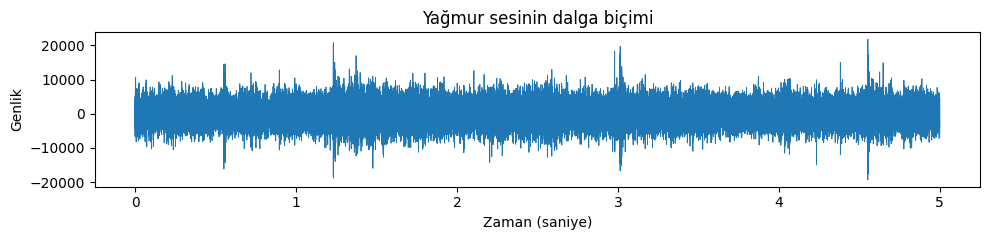

Köpek havlaması | 1-100032-A-0.wav


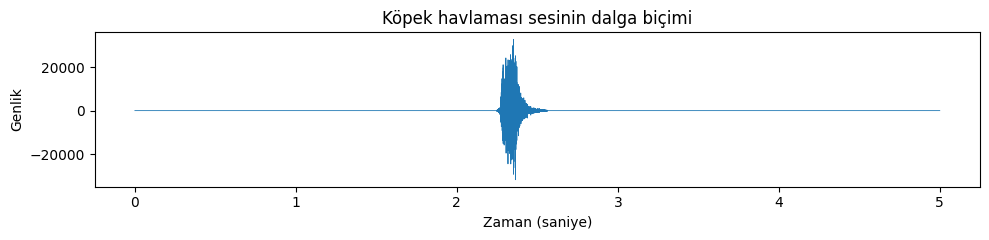

In [2]:
from urllib.request import urlretrieve

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

ses_klasoru = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master/audio/"
ornek_sesler = {"rain": "Yağmur", "dog": "Köpek havlaması"}

for kategori, turkce_ad in ornek_sesler.items():
    # Bu ses türüne ait ilk dosyanın adını tablodan alıyorum.
    dosya_adi = ses_kayitlari.loc[
        ses_kayitlari["category"] == kategori, "filename"
    ].iloc[0]

    # Ses dosyasını indirip içindeki ölçümleri okuyorum.
    urlretrieve(ses_klasoru + dosya_adi, dosya_adi)
    ornekleme_hizi, ses = wavfile.read(dosya_adi)

    print(f"{turkce_ad} | {dosya_adi}")
    display(Audio(filename=dosya_adi))

    # Her ölçümün kaydın kaçıncı saniyesine denk geldiğini hesaplıyorum.
    zaman = np.arange(len(ses)) / ornekleme_hizi

    plt.figure(figsize=(10, 2.5))
    plt.plot(zaman, ses, linewidth=0.6)
    plt.title(f"{turkce_ad} sesinin dalga biçimi")
    plt.xlabel("Zaman (saniye)")
    plt.ylabel("Genlik")
    plt.tight_layout()
    plt.show()

İncelediğim yağmur kaydında ses beş saniye boyunca devam ederken köpek kaydında kısa ve belirgin bir havlama gördüm. Bu iki örnek, sesin zaman içindeki değişiminin sınıflandırmada kullanılabilecek bir özellik olduğunu düşündürüyor.

### İlk denemede RMS ile ses düzeyini ölçme
Ses kaydını kısa aralıklara bölerek her aralığın RMS değerini hesapladım. Bu değerlerin ortalaması genel düzeyi, standart sapması ise zaman içindeki değişimi özetliyor. Kısa ve güçlü bir havlama, uzun sessiz bölümlerle birlikte değerlendirildiğinde düşük ortalama verebilir. Bu nedenle iki ölçüyü birlikte kullandım. Bu hücre iki örneği anlamak için yazılmış ilk denemedir. Daha aşağıdaki `kayit_ozelliklerini_cikar()` fonksiyonu modelin bütün 16 özelliğini üretir.

In [3]:
import librosa
import pandas as pd

def ses_ozelliklerini_cikar(dosya_yolu):
    # Ses dosyasını okuyup tüm kayıtlar için aynı örnekleme hızını kullanıyorum.
    ses, ornekleme_hizi = librosa.load(dosya_yolu, sr=22050, mono=True)

    # Kaydı kısa aralıklarla inceleyip her aralıkta ses düzeyini hesaplıyorum.
    rms = librosa.feature.rms(y=ses, frame_length=1024, hop_length=512)[0]

    return {
        "rms_ortalama": rms.mean(),
        "rms_standart_sapma": rms.std()
    }

sonuclar = []

for kategori, turkce_ad in ornek_sesler.items():
    dosya_adi = ses_kayitlari.loc[
        ses_kayitlari["category"] == kategori, "filename"
    ].iloc[0]

    ozellikler = ses_ozelliklerini_cikar(dosya_adi)
    sonuclar.append({"ses_turu": turkce_ad, **ozellikler})

ozellik_tablosu = pd.DataFrame(sonuclar)
display(ozellik_tablosu.round(4))

,ses_turu,rms_ortalama,rms_standart_sapma
0,Yağmur,0.0868,0.0112
1,Köpek havlaması,0.0075,0.0408


### İki örneğin sayısal yorumu
Yağmurun RMS ortalaması 0,0868, havlamanınki 0,0075 çıktı. Yağmur kayıt boyunca devam ederken havlama kısa bir aralıkta duyulduğu için bu farkı gözlemledim. RMS standart sapması havlamada 0,0408, yağmurda 0,0112. Havlama kaydının ses düzeyi zaman içinde daha fazla değişiyor. Bu ilk sonuç yalnızca seçtiğim iki kayda ait.

### Ses dosyalarını hazırlama
Kayıt listesindeki 400 dosyayı `esc10_sesler` klasöründe topladım. Daha önce indirilen dosya varsa tekrar indirmeden kullandım. Yeni indirmelerde geçici dosya adını, aktarım tamamlanınca gerçek WAV adına çevirdim. Böylece indirme yarıda kesilirse tamamlanmamış dosyayı hazır kayıt olarak saymıyorum.

In [6]:
from pathlib import Path
from urllib.request import urlretrieve
from urllib.error import HTTPError, URLError
from shutil import copyfile
from tqdm.auto import tqdm
import time

hedef_klasor = Path("esc10_sesler")
hedef_klasor.mkdir(exist_ok=True)

for dosya_adi in tqdm(
    ses_kayitlari["filename"],
    desc="Ses dosyaları hazırlanıyor"
):
    hedef_yol = hedef_klasor / dosya_adi

    # Tamamlanan dosyaları tekrar indirmiyorum.
    if hedef_yol.is_file():
        continue

    if Path(dosya_adi).is_file():
        copyfile(dosya_adi, hedef_yol)
        continue

    gecici_yol = hedef_yol.with_suffix(".part")

    # Geçici bağlantı hatalarında bekleyip yeniden deniyorum.
    for deneme in range(5):
        try:
            urlretrieve(ses_klasoru + dosya_adi, gecici_yol)
            gecici_yol.replace(hedef_yol)
            break

        except (HTTPError, URLError) as hata:
            # Bulunamayan veya erişime kapalı dosyaları ayrıca bildiriyorum.
            if isinstance(hata, HTTPError):
                if hata.code not in [429, 500, 502, 503, 504]:
                    raise

            if deneme == 4:
                raise

            bekleme = 5 * (deneme + 1)
            tqdm.write(
                f"{dosya_adi}: bağlantı hatası. "
                f"{bekleme} saniye sonra yeniden denenecek."
            )
            time.sleep(bekleme)

    # Sunucuya arka arkaya çok hızlı istek göndermiyorum.
    time.sleep(0.3)

hazir_sayisi = sum(
    (hedef_klasor / dosya_adi).is_file()
    for dosya_adi in ses_kayitlari["filename"]
)

print(f"Hazır ses dosyası: {hazir_sayisi} / {len(ses_kayitlari)}")

Ses dosyaları hazırlanıyor:   0%|          | 0/400 [00:00<?, ?it/s]

1-85362-A-0.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
1-85362-A-0.wav: bağlantı hatası. 10 saniye sonra yeniden denenecek.
1-85362-A-0.wav: bağlantı hatası. 15 saniye sonra yeniden denenecek.
1-85362-A-0.wav: bağlantı hatası. 20 saniye sonra yeniden denenecek.
1-91359-A-11.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-101676-A-10.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-101676-A-10.wav: bağlantı hatası. 10 saniye sonra yeniden denenecek.
2-107351-A-20.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-107351-B-20.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-109505-A-21.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-117271-A-0.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-117271-A-0.wav: bağlantı hatası. 10 saniye sonra yeniden denenecek.
2-117625-A-10.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-124662-A-11.wav: bağlantı hatası. 5 saniye sonra yeniden denenecek.
2-124662-A-11.wav: bağlant

## Her ses kaydını 16 sayısal özelliğe dönüştürme
İki örnekte gördüğüm farklılıkları 400 kayıt için ölçmek amacıyla `kayit_ozelliklerini_cikar()` fonksiyonunu yazdım. Fonksiyon her kaydı tek kanallı ve saniyede 22.050 örnek içeren bir sinyal olarak okuyor. Böylece bütün kayıtları aynı örnekleme hızında işliyorum.

| Özellik | Bu projedeki anlamı | Sütun sayısı |
|---|---|---:|
| RMS ortalaması | Kısa aralıklardaki ses düzeylerinin genel ortalaması | 1 |
| RMS standart sapması | Ses düzeyinin kayıt boyunca değişkenliği | 1 |
| Ortalama sıfır geçiş oranı | Dalganın pozitif ve negatif değerler arasındaki geçiş sıklığının özeti | 1 |
| MFCC ortalamaları | Sesin frekans yapısını ve tınısını özetleyen katsayılar | 13 |

RMS ve sıfır geçiş oranında 1024 örneklik çerçeveler ile 512 örneklik adımlar kullanıyorum. MFCC çağrısında spektral çerçeve ayarlarını ayrıca belirtmediğim için kütüphanenin varsayılanları kullanılıyor. Her MFCC katsayısının zaman boyunca ortalamasını alıyorum. Bu özetleme, ses içindeki olayların gerçekleşme sırası hakkındaki ayrıntıları azaltabilir.

Her dosya için 16 özellik çıkarıp yanına `dosya_adi`, `ses_turu` ve `fold` bilgilerini ekledim. Sonuçta her satırı bir kaydı temsil eden 400 satır ve 19 sütunluk CSV oluşturdum. Kullanıcıdan gelen kaydı tahmin ederken de aynı fonksiyonu çağırıyorum.

In [7]:
def kayit_ozelliklerini_cikar(dosya_yolu):
    ses, ornekleme_hizi = librosa.load(dosya_yolu, sr=22050, mono=True)

    # Önceki örnekteki gibi kısa aralıkların ses düzeyini ölçüyorum.
    rms = librosa.feature.rms(y=ses, frame_length=1024, hop_length=512)[0]

    sifir_gecisleri = librosa.feature.zero_crossing_rate(
        y=ses, frame_length=1024, hop_length=512
    )[0]

    # Her zaman aralığı için 13 MFCC katsayısı hesaplıyorum.
    mfcc = librosa.feature.mfcc(y=ses, sr=ornekleme_hizi, n_mfcc=13)

    ozellikler = {
        "rms_ortalama": rms.mean(),
        "rms_standart_sapma": rms.std(),
        "sifir_gecis_ortalama": sifir_gecisleri.mean()
    }

    # Her katsayının zaman boyunca ortalamasını alıp ayrı bir sütuna yazıyorum.
    for sira, ortalama in enumerate(mfcc.mean(axis=1), start=1):
        ozellikler[f"mfcc_{sira}_ortalama"] = ortalama

    return ozellikler


satirlar = []

for kayit in tqdm(
    ses_kayitlari.itertuples(index=False),
    total=len(ses_kayitlari),
    desc="Ses özellikleri çıkarılıyor"
):
    dosya_yolu = hedef_klasor / kayit.filename
    satir = {
        "dosya_adi": kayit.filename,
        "ses_turu": kayit.category,
        "fold": kayit.fold
    }
    satir.update(kayit_ozelliklerini_cikar(dosya_yolu))
    satirlar.append(satir)

# Her kayıt bir satır olacak şekilde tabloyu oluşturup CSV'ye kaydediyorum.
ozellik_tablosu = pd.DataFrame(satirlar)
ozellik_tablosu.to_csv("esc10_ses_ozellikleri.csv", index=False)

print("Tablo boyutu:", ozellik_tablosu.shape)
print("Farklı ses türü:", ozellik_tablosu["ses_turu"].nunique())
print("Eksik değer:", ozellik_tablosu.isna().sum().sum())
display(ozellik_tablosu.head(3).round(4))

Ses özellikleri çıkarılıyor:   0%|          | 0/400 [00:00<?, ?it/s]

Tablo boyutu: (400, 19)
Farklı ses türü: 10
Eksik değer: 0


,dosya_adi,ses_turu,fold,rms_ortalama,rms_standart_sapma,sifir_gecis_ortalama,mfcc_1_ortalama,mfcc_2_ortalama,mfcc_3_ortalama,mfcc_4_ortalama,mfcc_5_ortalama,mfcc_6_ortalama,mfcc_7_ortalama,mfcc_8_ortalama,mfcc_9_ortalama,mfcc_10_ortalama,mfcc_11_ortalama,mfcc_12_ortalama,mfcc_13_ortalama
0,1-100032-A-0.wav,dog,1,0.0075,0.0408,0.0134,-600.940186,4.694300,-8.5059,-4.2766,-0.8186,-1.9734,-0.294600,0.8254,0.8215,0.4409,-0.4767,-0.2463,-0.8608
1,1-110389-A-0.wav,dog,1,0.0064,0.0340,0.0069,-586.231384,10.243300,-2.9993,-2.8704,-0.1640,0.6985,-1.224400,0.0941,-0.0901,0.4176,0.6170,0.9444,1.6372
2,1-116765-A-41.wav,chainsaw,1,0.1606,0.0648,0.0998,-59.360401,84.921097,-31.3957,5.9807,-29.7535,-4.5117,-20.784901,1.9699,-10.7117,5.9609,-9.0644,-5.9232,-9.5926


## Yağmur ve havlama kayıtlarını toplu karşılaştırma
Oluşturduğum CSV'yi Pandas ile yeniden okudum. Son test için ayırdığım beşinci fold'u bu keşif grafiğine dahil etmedim. Kalan 320 kayıttan 32 yağmur ve 32 havlama kaydını seçtim. Her nokta bir kaydı gösteriyor. Sağa gidildikçe ortalama RMS, yukarı gidildikçe RMS değişkenliği artıyor. Özet tablodaki ortanca, uç değerlerin etkisini azaltarak grupların tipik değerlerini karşılaştırmamı sağlıyor.

,kayit_sayisi,ortanca_rms_ortalama,ortanca_rms_standart_sapma
ses_turu,,,
dog,32,0.0456,0.0763
rain,32,0.0859,0.0159


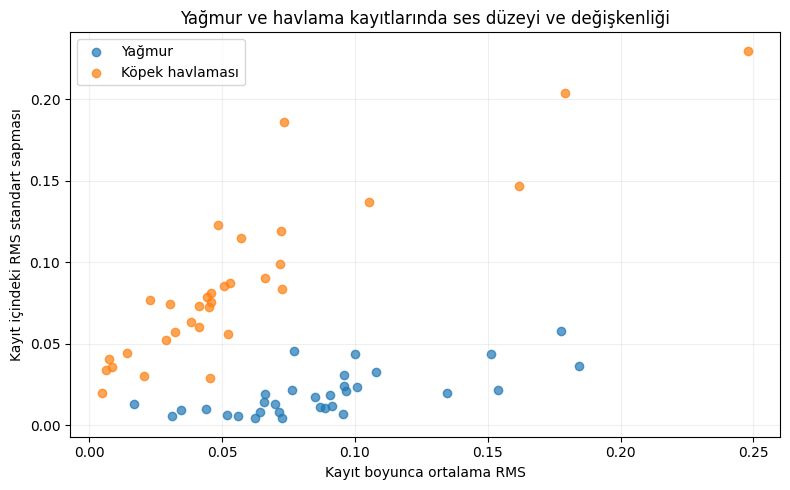

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Hazırladığım özellik tablosunu CSV dosyasından okuyorum.
veri = pd.read_csv("esc10_ses_ozellikleri.csv")

# Son test için 5. grubu ayırıp yağmur ve köpek kayıtlarını seçiyorum.
gelistirme_verisi = veri.loc[veri["fold"] != 5]
secili_kayitlar = gelistirme_verisi.loc[
    gelistirme_verisi["ses_turu"].isin(["rain", "dog"])
]

# Her türde kaç kayıt olduğunu ve ortanca RMS değerlerini gösteriyorum.
ozet = secili_kayitlar.groupby("ses_turu").agg(
    kayit_sayisi=("dosya_adi", "count"),
    ortanca_rms_ortalama=("rms_ortalama", "median"),
    ortanca_rms_standart_sapma=("rms_standart_sapma", "median")
)
display(ozet.round(4))

# Her nokta bir ses kaydını temsil ediyor.
plt.figure(figsize=(8, 5))

for tur, ad, renk in [
    ("rain", "Yağmur", "tab:blue"),
    ("dog", "Köpek havlaması", "tab:orange")
]:
    grup = secili_kayitlar.loc[secili_kayitlar["ses_turu"] == tur]
    plt.scatter(
        grup["rms_ortalama"],
        grup["rms_standart_sapma"],
        label=ad, color=renk, alpha=0.7
    )

plt.title("Yağmur ve havlama kayıtlarında ses düzeyi ve değişkenliği")
plt.xlabel("Kayıt boyunca ortalama RMS")
plt.ylabel("Kayıt içindeki RMS standart sapması")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

İncelediğim 32 yağmur ve 32 köpek havlaması kaydında, ortalama RMS değerinin ortancası yağmurda daha yüksekti (0.0859 ve 0.0456). Buna karşılık kayıt içindeki ses düzeyinin değişkenliği havlamada daha yüksekti (0.0763 ve 0.0159). Bu sonuç, kısa havlamalar ve aralarındaki sessizliğin ilk örnekte oluşturduğu örüntüyle uyumluydu.

## Eğitim doğrulama ve test gruplarını ayırma
Hazır fold 1–3 içindeki 240 kaydı eğitim, fold 4 içindeki 80 kaydı model seçimi için doğrulama grubu yaptım. Fold 5 içindeki 80 kaydı son teste ayırdım. Hazır grupları koruyarak aynı kaynak kaydın parçalarının farklı gruplara dağılmasını önlemeyi amaçladım.

`X_egitim` ve `X_dogrulama` 16 sayısal ses özelliğini, `y_egitim` ve `y_dogrulama` ise gerçek etiketleri içeriyor. `dosya_adi`, `ses_turu` ve `fold` model girdilerinden çıkarılıyor. Böylece model tahminini sesten ölçülen özelliklerden öğreniyor.

### İlk model olarak Karar Ağacı
`fit()` özelliklerle doğru etiketler arasındaki ilişkileri öğreniyor. `predict()` verilen özelliklerden bir sınıf tahmini üretiyor. `max_depth=5` ağacın derinliğini sınırlıyor. `random_state=42` rastgele seçimlerin tekrarlanabilir olmasını sağlıyor. Doğruluk, doğru etiketlenen kayıt sayısının toplam kayıt sayısına oranıdır.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# İlk üç grubu eğitim, dördüncü grubu doğrulama için seçiyorum.
egitim = veri.loc[veri["fold"].isin([1, 2, 3])]
dogrulama = veri.loc[veri["fold"] == 4]

# Modele yalnızca sesten hesapladığım 16 sayısal özelliği veriyorum.
ozellik_sutunlari = veri.columns.drop(["dosya_adi", "ses_turu", "fold"])

X_egitim = egitim[ozellik_sutunlari]
y_egitim = egitim["ses_turu"]

X_dogrulama = dogrulama[ozellik_sutunlari]
y_dogrulama = dogrulama["ses_turu"]

# İlk denemede ağacın derinliğini 5 ile sınırlıyorum.
karar_agaci = DecisionTreeClassifier(max_depth=5, random_state=42)
karar_agaci.fit(X_egitim, y_egitim)

egitim_tahminleri = karar_agaci.predict(X_egitim)
dogrulama_tahminleri = karar_agaci.predict(X_dogrulama)

dogru_sayisi = (dogrulama_tahminleri == y_dogrulama).sum()

print("Eğitim tablosu:", X_egitim.shape)
print("Doğrulama tablosu:", X_dogrulama.shape)
print(f"Eğitim doğruluğu: %{100 * accuracy_score(y_egitim, egitim_tahminleri):.1f}")
print(f"Doğrulama doğruluğu: %{100 * accuracy_score(y_dogrulama, dogrulama_tahminleri):.1f}")
print(f"Doğru tahmin edilen doğrulama kaydı: {dogru_sayisi} / {len(y_dogrulama)}")

Eğitim tablosu: (240, 16)
Doğrulama tablosu: (80, 16)
Eğitim doğruluğu: %86.2
Doğrulama doğruluğu: %65.0
Doğru tahmin edilen doğrulama kaydı: 52 / 80


### Random Forest ile karşılaştırma
İkinci modelde 200 ağaç kullandım. Random Forest, eğitim verisinden farklı örneklemler ve özellik seçimleriyle kurduğu ağaçların tahminlerini birleştiriyor. İki modelde aynı 16 özelliği ve aynı veri gruplarını kullanarak model değişikliğinin doğrulama sonucunu karşılaştırdım.

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Başlangıç için 200 ağaç kullanıyorum.
rastgele_orman = RandomForestClassifier(n_estimators=200, random_state=42)
rastgele_orman.fit(X_egitim, y_egitim)

# İki modelin sonuçlarını aynı tabloda karşılaştırıyorum.
modeller = {
    "Karar Ağacı": karar_agaci,
    "Random Forest": rastgele_orman
}

sonuclar = []

for model_adi, model in modeller.items():
    tahminler = model.predict(X_dogrulama)
    dogru_sayisi = (tahminler == y_dogrulama).sum()

    sonuclar.append({
        "Model": model_adi,
        "Eğitim doğruluğu (%)": 100 * model.score(X_egitim, y_egitim),
        "Doğrulama doğruluğu (%)": 100 * accuracy_score(y_dogrulama, tahminler),
        "Doğru tahmin (80 kayıtta)": dogru_sayisi
    })

karsilastirma = pd.DataFrame(sonuclar)
display(karsilastirma.round(1))

,Model,Eğitim doğruluğu (%),Doğrulama doğruluğu (%),Doğru tahmin (80 kayıtta)
0,Karar Ağacı,86.2,65.0,52
1,Random Forest,100.0,75.0,60


### Model seçimi ve eğitim doğrulama farkı
Karar Ağacını, özellikler üzerinde koşullara dayalı ayrımlar kurduğu ve ilk karşılaştırma için anlaşılır olduğu için kullandım. Random Forest ise birden fazla ağacın tahminlerini birleştiriyor. İki modeli aynı eğitim ve doğrulama kayıtlarıyla karşılaştırdım.

| Model | Eğitim doğruluğu | Doğrulama doğruluğu | Doğru doğrulama tahmini |
|---|---:|---:|---:|
| Karar Ağacı | %86,2 | %65 | 52 / 80 |
| Random Forest | %100 | %75 | 60 / 80 |

Eğitimdeki başarıların daha yüksek olması, öğrenilen ayrımların yeni kayıtlarda aynı ölçüde işe yaramadığını gösteriyor ve aşırı öğrenme olasılığına işaret ediyor. Random Forest doğrulama grubunda sekiz ek doğru tahmin yaptığı için onu seçtim. %100 eğitim doğruluğu, eğitimde kullanılan kayıtlara ait bir sonuçtur.

Modeli seçtikten sonra ilk dört fold içindeki 320 kaydı birleştirip aynı ayarlarla yeniden eğitim yaptım. Beşinci fold içindeki 80 kaydı son test için kullandım.

## Seçilen modelin son testi
`clone()` seçtiğim Random Forest'ın ayarlarıyla yeni bir model oluşturuyor. Bu modeli ilk dört fold'un 320 kaydıyla eğitiyorum. Fold 5'teki gerçek etiketleri tahmin sırasında modele vermiyorum. Tahminleri ürettikten sonra etiketlerle karşılaştırarak başarıyı hesaplıyorum.

Karışıklık matrisinde satırlar gerçek sesleri, sütunlar tahmin edilen sesleri gösteriyor. Köşegendeki sayılar doğru tahminler. Diğer hücreler hangi seslerin karıştırıldığını gösteriyor.

Son eğitim kaydı: 320
Test kaydı: 80
Doğru tahmin: 66 / 80
Test doğruluğu: %82.5


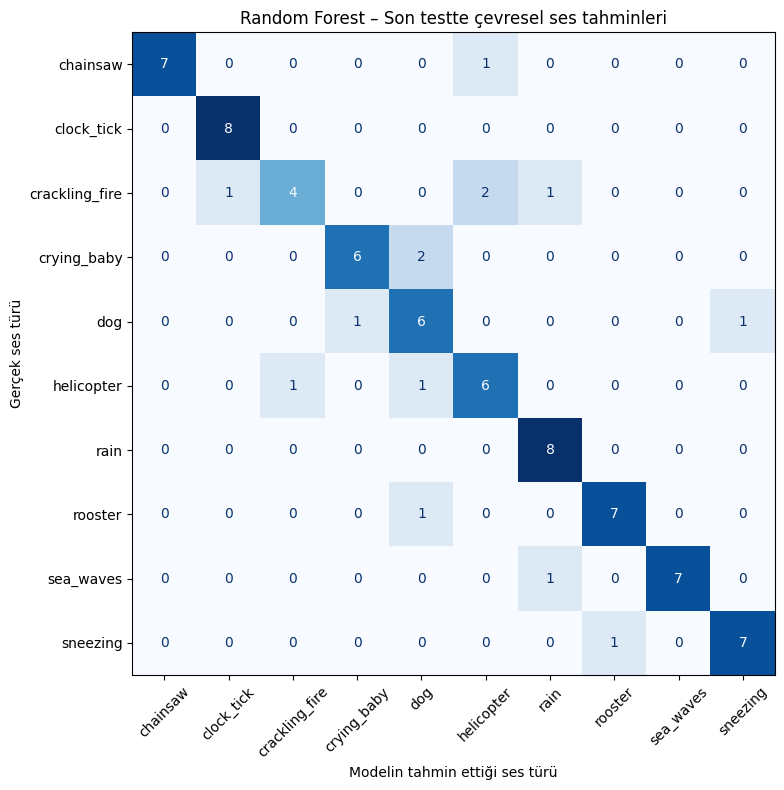

In [11]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# İlk dört grubu eğitim, beşinci grubu son test için kullanıyorum.
son_egitim = veri.loc[veri["fold"] != 5]
test = veri.loc[veri["fold"] == 5]

# Seçtiğim Random Forest'ın ayarlarını kopyalayıp 320 kayıtla eğitiyorum.
son_model = clone(rastgele_orman)
son_model.fit(son_egitim[ozellik_sutunlari], son_egitim["ses_turu"])

# Test kayıtlarının etiketlerini tahmin edip gerçek ses türleriyle karşılaştırıyorum.
gercek_turler = test["ses_turu"]
test_tahminleri = son_model.predict(test[ozellik_sutunlari])
dogru_sayisi = (test_tahminleri == gercek_turler).sum()

print("Son eğitim kaydı:", len(son_egitim))
print("Test kaydı:", len(test))
print(f"Doğru tahmin: {dogru_sayisi} / {len(test)}")
print(f"Test doğruluğu: %{100 * accuracy_score(gercek_turler, test_tahminleri):.1f}")

fig, eksen = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    gercek_turler,
    test_tahminleri,
    labels=son_model.classes_,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False,
    ax=eksen
)
eksen.set_title("Random Forest – Son testte çevresel ses tahminleri")
eksen.set_xlabel("Modelin tahmin ettiği ses türü")
eksen.set_ylabel("Gerçek ses türü")
plt.tight_layout()
plt.show()

### Sonucun kapsamı ve sınırlılıklar
Model son testte 80 kaydın 66'sını doğru tanıdı ve %82,5 doğruluk elde etti. Yağmur ve saat tıklamasının sekizer örneğinin tamamı doğru tanındı. Ateş çıtırtısında sekiz örneğin dördü doğru. Kalan ateş kayıtlarının ikisi helikopter, biri saat tıklaması, biri yağmur olarak etiketlendi.

Bu puan tek bir 80 kayıtlık test grubuna ait. Veri seti dışındaki telefon kayıtlarında başarıyı henüz ölçmedim. Özelliklerin zaman boyunca ortalamasını almak, kısa olayları ayırt etmekte yetersiz kalabilir. Bu olasılığı değerlendirmek için zamansal özelliklerle karşılaştırmalı deney yapılabilir. Doğrulama %75, son test %82,5 sonucu farklı gruplarda ölçüldü. Bu farkı yalnızca eğitim kaydı sayısının artmasına bağlayamam.

### Eğitim ve test matrislerinin boyutu
Aşağıdaki hücre, son eğitimde 320 satır ve testte 80 satır bulunduğunu, her iki tabloda da 16 özellik kullanıldığını gösterir. Beklenen boyutlar `(320, 16)` ve `(80, 16)` değerleridir.

In [12]:
print("Son eğitim özellik matrisi:", son_egitim[ozellik_sutunlari].shape)
print("Test özellik matrisi:", test[ozellik_sutunlari].shape)


Son eğitim özellik matrisi: (320, 16)
Test özellik matrisi: (80, 16)


## Kullanıcı kaydıyla tahmin uygulaması
`tahmin_et(dosya_yolu)` fonksiyonu, dosyadan 16 özelliği çıkarıp bunları eğitimde kullanılan sütun sırasına yerleştiriyor. `son_model.predict()` sınıf etiketini üretiyor. `turkce_etiketler` sözlüğü bu etiketi kullanıcıya gösterilecek Türkçe karşılığına çeviriyor.

Bu hücreyi çalıştırıp **Dosyaları Seç** düğmesinden yaklaşık beş saniyelik bir WAV kaydı yükleyebilirsiniz. Uygulama dosyayı dinletir ve tahminini gösterir. Dosyanız yoksa **Cancel upload** ile yüklemeyi iptal edip sonraki hazır örnek hücresini çalıştırabilirsiniz. **Tümünü çalıştır** sırasında da bu hücre kullanıcı seçimi bekler.

Model her dosyaya öğrendiği 10 sınıftan birini verir. Sınıf dışı bir sesin veya birden fazla ses içeren kaydın nasıl değerlendirileceği ileride ayrıca incelenebilir. Kayıt süresini bu sürümde otomatik olarak beş saniyeye sabitlemiyorum. İlk denemelerde veri setine benzer uzunlukta dosya seçmek karşılaştırmayı kolaylaştırır.

In [13]:
from google.colab import files
from IPython.display import Audio, display

turkce_etiketler = {
    "chainsaw": "Motorlu testere",
    "clock_tick": "Saat tıklaması",
    "crackling_fire": "Ateş çıtırtısı",
    "crying_baby": "Bebek ağlaması",
    "dog": "Köpek havlaması",
    "helicopter": "Helikopter",
    "rain": "Yağmur",
    "rooster": "Horoz ötüşü",
    "sea_waves": "Deniz dalgaları",
    "sneezing": "Hapşırma"
}

def tahmin_et(dosya_yolu):
    # Yeni kaydı eğitimde kullandığım 16 özelliğe dönüştürüyorum.
    ozellikler = kayit_ozelliklerini_cikar(dosya_yolu)
    yeni_kayit = pd.DataFrame([ozellikler], columns=ozellik_sutunlari)

    tahmin = son_model.predict(yeni_kayit)[0]
    return turkce_etiketler[tahmin]

yuklenen_dosyalar = files.upload()

for dosya_adi in yuklenen_dosyalar:
    print(f"Dosya: {dosya_adi}")
    display(Audio(filename=dosya_adi))
    print(f"Modelin tahmini: {tahmin_et(dosya_adi)}")

### Hazır test kaydıyla uygulamayı deneme
Dosya yüklemeden de fonksiyonu deneyebilmek için son test grubundaki bir yağmur kaydını seçtim. Kayıt dinletiliyor, gerçek etiketi ve modelin Türkçe tahmini birlikte gösteriliyor.

In [14]:
ornek = test.loc[test["ses_turu"] == "rain"].iloc[0]
dosya_yolu = hedef_klasor / ornek["dosya_adi"]

display(Audio(filename=str(dosya_yolu)))
print("Gerçek ses: Yağmur")
print("Modelin tahmini:", tahmin_et(dosya_yolu))

Gerçek ses: Yağmur
Modelin tahmini: Yağmur


### Üç kayıtta gerçek etiket ve tahmin
Yağmur, havlama ve ateş çıtırtısından birer test kaydı seçtim. Her dosyada gerçek etiket ile tahmini karşılaştırdım. Ateş çıtırtısını, son testte modelin en çok zorlandığı sınıf olduğu için örnekler arasına ekledim.

In [15]:
ornek_sonuclari = []

for ses_turu in ["rain", "dog", "crackling_fire"]:
    # Her ses türü için test grubundaki ilk kaydı seçiyorum.
    kayit = test.loc[test["ses_turu"] == ses_turu].iloc[0]
    dosya_yolu = hedef_klasor / kayit["dosya_adi"]

    gercek_ses = turkce_etiketler[ses_turu]
    tahmin = tahmin_et(dosya_yolu)

    ornek_sonuclari.append({
        "Dosya adı": kayit["dosya_adi"],
        "Gerçek ses": gercek_ses,
        "Modelin tahmini": tahmin,
        "Sonuç": "Doğru" if tahmin == gercek_ses else "Yanlış"
    })

ornek_tahmin_tablosu = pd.DataFrame(ornek_sonuclari)
display(ornek_tahmin_tablosu)

,Dosya adı,Gerçek ses,Modelin tahmini,Sonuç
0,5-181766-A-10.wav,Yağmur,Yağmur,Doğru
1,5-203128-A-0.wav,Köpek havlaması,Köpek havlaması,Doğru
2,5-186924-A-12.wav,Ateş çıtırtısı,Yağmur,Yanlış


### Üç örnek tahminin yorumu
Tablodaki yağmur ve köpek havlaması kayıtları doğru tanındı. Ateş çıtırtısı ise yağmur olarak tahmin edildi. Bu hata, karışıklık matrisindeki ateş çıtırtısı satırında görülen hatalardan biridir.

Bu üç dosya, modelin eğitimde görmediği test grubundan seçildi ve 80 kayıtlık test sonucuna zaten dahil. Örnek tablo uygulamanın davranışını somutlaştırıyor. Genel değerlendirmede 80 kaydın tamamında ölçülen %82,5 doğruluğu kullanıyorum. Veri seti dışından yüklenen bir telefon kaydıyla yapılmış deney bu defterde henüz yer almıyor.

## Veri sözlüğü
Özellik CSV'sini açan kişinin her sütunun anlamını ve görevini anlayabilmesi için veri sözlüğü hazırladım. Sütun adlarını CSV ile karşılaştıran `assert` kontrolü eşleşmeyi doğruluyor. `utf-8-sig` kodlaması, CSV'nin Excel'de Türkçe karakterlerle açılmasını kolaylaştırıyor.

In [16]:
# Her sütunun veri tipini, projedeki görevini ve anlamını yazıyorum.
satirlar = [
    ["dosya_adi", "Metin", "Kayıt kimliği", "Ses kaydının WAV dosya adı."],
    ["ses_turu", "Kategorik", "Hedef", "Modelin tahmin etmeyi öğrendiği gerçek ses etiketi."],
    ["fold", "Tam sayı", "Grup numarası", "Kaydın veri setindeki hazır grubu (1–5)."],
    ["rms_ortalama", "Ondalıklı sayı", "Model girdisi",
     "Kısa zaman aralıklarında ölçülen ses düzeylerinin ortalaması."],
    ["rms_standart_sapma", "Ondalıklı sayı", "Model girdisi",
     "Ses düzeyinin kayıt boyunca ne kadar değiştiğini gösterir."],
    ["sifir_gecis_ortalama", "Ondalıklı sayı", "Model girdisi",
     "Kısa zaman aralıklarında ses dalgasının işaret değiştirme oranının ortalaması."]
]

# Özellik çıkarırken MFCC sütunlarını 1'den 13'e kadar adlandırmıştım.
for sira in range(1, 14):
    satirlar.append([
        f"mfcc_{sira}_ortalama",
        "Ondalıklı sayı",
        "Model girdisi",
        f"Sesin tınısını özetleyen {sira}. MFCC sütununun zaman boyunca ortalaması."
    ])

veri_sozlugu = pd.DataFrame(
    satirlar,
    columns=["Sütun adı", "Veri tipi", "Projede görevi", "Anlamı"]
)

# Sözlükteki adları, kullandığım CSV'nin gerçek sütunlarıyla karşılaştırıyorum.
assert veri_sozlugu["Sütun adı"].tolist() == veri.columns.tolist()

veri_sozlugu.to_csv("veri_sozlugu.csv", index=False, encoding="utf-8-sig")
display(veri_sozlugu)
print(f"Veri sözlüğü kaydedildi: {len(veri_sozlugu)} sütun tanımlandı.")

,Sütun adı,Veri tipi,Projede görevi,Anlamı
0,dosya_adi,Metin,Kayıt kimliği,Ses kaydının WAV dosya adı.
1,ses_turu,Kategorik,Hedef,Modelin tahmin etmeyi öğrendiği gerçek ses eti...
2,fold,Tam sayı,Grup numarası,Kaydın veri setindeki hazır grubu (1–5).
3,rms_ortalama,Ondalıklı sayı,Model girdisi,Kısa zaman aralıklarında ölçülen ses düzeyleri...
4,rms_standart_sapma,Ondalıklı sayı,Model girdisi,Ses düzeyinin kayıt boyunca ne kadar değiştiği...
5,sifir_gecis_ortalama,Ondalıklı sayı,Model girdisi,Kısa zaman aralıklarında ses dalgasının işaret...
6,mfcc_1_ortalama,Ondalıklı sayı,Model girdisi,Sesin tınısını özetleyen 1. MFCC sütununun zam...
7,mfcc_2_ortalama,Ondalıklı sayı,Model girdisi,Sesin tınısını özetleyen 2. MFCC sütununun zam...
8,mfcc_3_ortalama,Ondalıklı sayı,Model girdisi,Sesin tınısını özetleyen 3. MFCC sütununun zam...
9,mfcc_4_ortalama,Ondalıklı sayı,Model girdisi,Sesin tınısını özetleyen 4. MFCC sütununun zam...


Veri sözlüğü kaydedildi: 19 sütun tanımlandı.


## Veri kalitesini kontrol etme
`isna()` eksik hücreleri, `duplicated()` yinelenen dosya adlarını, `isinf()` sayısal özelliklerde sonsuz değerleri kontrol ediyor. Bu kontroller hangi temizlik işlemlerine gerek olduğunu değerlendirmemi sağlıyor.

In [17]:
import numpy as np

eksik_hucre = veri.isna().sum().sum()
tekrar_dosya = veri["dosya_adi"].duplicated().sum()
sonsuz_deger = np.isinf(veri[ozellik_sutunlari].to_numpy()).sum()

print("Eksik hücre sayısı:", eksik_hucre)
print("Tekrarlanan dosya adı sayısı:", tekrar_dosya)
print("16 ses özelliğindeki sonsuz değer sayısı:", sonsuz_deger)

Eksik hücre sayısı: 0
Tekrarlanan dosya adı sayısı: 0
16 ses özelliğindeki sonsuz değer sayısı: 0


### Veri kontrolünün sonucu
400 satırlık tabloda eksik hücre, yinelenen dosya adı ve 16 sayısal özellikte sonsuz değer bulmadım. Bu kontroller sonucunda satır silmeye veya eksik değer doldurmaya gerek kalmadı. Dosya adı kontrolü aynı dosyanın tabloda tekrar listelenip listelenmediğini inceliyor. Farklı adlara sahip seslerin içerik olarak aynı olup olmadığını bu kontrolle ölçmüyorum.

## Özelliklerin özet istatistikleri
Test dışında kalan 320 kayıtta `describe()` ile özet çıkardım. Tablonun her satırında bir özellik var. `count` kayıt sayısı, `mean` ortalama, `std` kayıtlar arasındaki standart sapma, `min` ve `max` uç değerlerdir. `50%` ortancayı, `25%` ve `75%` alt ve üst çeyrekleri gösterir. `rms_standart_sapma` özelliği tek kaydın içindeki değişimi ölçerken bu özetin `std` sütunu aynı özelliğin kayıtlar arasındaki değişimini gösterir.

In [18]:
# Geliştirme grubundaki 16 ses özelliğinin özetini çıkarıyorum.
istatistik_ozeti = gelistirme_verisi[ozellik_sutunlari].describe().T

# Her satırda bir özellik görünecek şekilde tabloyu gösteriyorum.
display(istatistik_ozeti.round(4))

,count,mean,std,min,25%,50%,75%,max
rms_ortalama,320.0,0.0740,0.0586,0.0020,0.0230,0.0642,0.1063,0.2696
rms_standart_sapma,320.0,0.0505,0.0403,0.0026,0.0202,0.0431,0.0699,0.2913
sifir_gecis_ortalama,320.0,0.1194,0.0828,0.0069,0.0560,0.0996,0.1666,0.4480
mfcc_1_ortalama,320.0,-272.3856,181.7225,-738.4089,-425.5588,-286.9086,-85.7456,23.2160
mfcc_2_ortalama,320.0,67.6626,48.7071,-44.7956,31.5903,60.5222,94.0521,229.2914
mfcc_3_ortalama,320.0,-11.0620,30.2028,-122.8466,-29.1287,-9.8984,3.8834,98.8238
mfcc_4_ortalama,320.0,8.2664,19.5124,-60.5068,-2.9129,7.7599,20.2586,65.9727
mfcc_5_ortalama,320.0,-3.6348,15.7544,-73.3465,-13.0094,-3.6743,6.3563,46.5500
mfcc_6_ortalama,320.0,4.7421,12.3530,-29.5646,-1.6009,3.5842,12.2669,59.7428
mfcc_7_ortalama,320.0,-4.1026,11.1625,-40.0164,-9.6834,-3.2200,2.7170,21.1746


### Keşif bulguları
- Veri setindeki 10 ses türünün her birinde 40 kayıt bulunuyor. Sınıflar örnek sayısı bakımından dengeli.
- Geliştirme grubundaki 320 kaydın ortalama RMS değerleri 0,0020 ile 0,2696 arasında. Kayıtların ortadaki yarısı 0,0230–0,1063 aralığında.
- İncelediğim 32 yağmur ve 32 havlama kaydında, RMS ortalamasının ortancası yağmurda 0,0859, havlamada 0,0456. Bu örneklerde yağmur kayıtlarının tipik ses düzeyi daha yüksek.
- RMS standart sapmasının ortancası havlamada 0,0763, yağmurda 0,0159. Havlamaların zaman içindeki ses düzeyi daha değişken. Bu sonuç dalga grafiklerindeki kısa havlama ve sessizlik örüntüsüyle uyumlu.

Bu inceleme iki sınıf arasında yararlı olabilecek farkları gösteriyor. Bütün 10 sınıftaki tahmin başarısını eğitim ve ayrı değerlendirme gruplarıyla ölçtüm.